<table style="width: 100%; border: none; background: #f8f9fa; padding: 20px; border-radius: 10px;">
    <tr>
        <td style="width: 22%; border: none; vertical-align: middle; text-align: center;">
            <img src="https://www.inf.ucv.cl/wp-content/uploads/2020/05/logo_escuela.jpg" width="170">
        </td>
        <td style="width: 56%; border: none; vertical-align: middle; text-align: center; padding: 0 20px;">
            <h1 style="font-size: 28px; color: #1a3b5c; margin-bottom: 16px; border-bottom: 2px solid #1a3b5c; padding-bottom: 8px;">Tarea 2: Clasificacion, Costos Asimetricos y Arboles</h1>
            <p style="font-size: 16px; margin: 8px 0;"><strong>Pontificia Universidad Catolica de Valparaiso</strong><br>
            <strong>Escuela de Ingenieria Informatica</strong></p>
            <p style="font-size: 14px; color: #333; margin: 12px 0;"><strong>OII432 Machine Learning</strong><br>
            <strong>Semestre: 2-2026</strong><br>
            <strong>Profesor: Carlos Valle</strong></p>
        </td>
        <td style="width: 22%; border: none; vertical-align: middle; text-align: center;">
            <img src="https://upload.wikimedia.org/wikipedia/commons/c/cb/PUCV_Escudo2016.svg" width="110">
        </td>
    </tr>
</table>

# Pregunta 2: desafío Kaggle
Integrantes:
- Nelson Fuentes
- Eduardo Pérez
- Eduardo Sandoval
- Ricardo Pastén

Se predice si una licitación quedará desierta con información disponible al publicarla. La pauta adjunta confirma que la métrica es F1 para la clase desierta.

> Las salidas previas se limpiaron durante esta revisión. Ejecutar el notebook completo desde un kernel limpio para regenerar métricas, figuras y submission.

# Importación de librerías

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, brier_score_loss, confusion_matrix,
    f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score
)
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
TARGET = "y_desierta"
plt.rcParams["figure.figsize"] = (12, 5)
sns.set_palette("deep")
print(f"NumPy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

NumPy 1.26.2 | pandas 2.3.3 | scikit-learn 1.9.1


# Explicación de los datos

### Carga de datos

In [25]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")
assert list(pd.read_csv("sample_submission.csv", nrows=0).columns) == ["id", TARGET]
# Solo se leen los identificadores de la plantilla; sus etiquetas de ejemplo se ignoran.
sample_submission_df = pd.read_csv("sample_submission.csv", usecols=["id"])

### Inspección e integridad

In [26]:
for nombre, df in {"train": train_df, "test": test_df}.items():
    print(nombre, df.shape)
    display(df.head(3))

train (152553, 24)


,id,pub_fecha,pub_titulo,pub_descripcion,pub_monto_estimado,pub_moneda,pub_metodo,pub_modalidad,pub_n_items,pub_cantidad_total,...,pub_cierre,pub_dias_postulacion,pub_tiene_consultas,pub_dias_consultas,comprador,comprador_id,comprador_rut,region,direccion,y_desierta
0,248328745624,2024-03-25T15:32:20Z,LP04-2024 AV. UNO SUR AYSEN,"CONSTRUCCIÓN CALZADA H.C.V. AVENIDA UNO SUR, P...",NaN,NaN,open,Licitación Pública MOP (O1),1,1.0,...,2024-04-12T10:00:00Z,17.769,False,11.0,SERVICIO DE VIVIENDA Y URBANIZACION XI REGION ...,CL-MP-1653,618230007,Región Aysén del General Carlos Ibáñez del Campo,RAMON FREIRE Nº 5,0
1,760555527084,2024-03-21T14:29:28Z,LICITACION PUBLICA PARA OBRAS DE INFRAESTRUCTU...,licitar las obras de infraestructura de mejora...,NaN,NaN,open,Licitación Pública entre a 2000 y 5000 UTM (LQ),1,1.0,...,2024-04-15T20:00:00Z,25.230,False,21.0,CORPORACION MUNICIPAL DE EDUCACION Y SALUD DE ...,CL-MP-1274286,709255002,Región Metropolitana de Santiago,O'HIGGINS 840,1
2,224829110991,2024-01-26T12:37:41Z,ADQUISICION DE INSUMOS DE ENFERMERÍA PARA DSM,ADQUISICION DE INSUMOS DE ENFERMERÍA PARA USUA...,3500000.0,CLP,open,Licitación Pública Menor a 100 UTM (L1),55,12150.0,...,2024-02-01T13:24:00Z,6.032,False,3.0,I MUNICIPALIDAD DE CHANCO | I MUNICIPALIDAD DE...,CL-MP-4391,69120300K,Región del Maule,Ignacio Carrera Pinto Nº 31,0


test (21829, 23)


,id,pub_fecha,pub_titulo,pub_descripcion,pub_monto_estimado,pub_moneda,pub_metodo,pub_modalidad,pub_n_items,pub_cantidad_total,...,pub_inicio,pub_cierre,pub_dias_postulacion,pub_tiene_consultas,pub_dias_consultas,comprador,comprador_id,comprador_rut,region,direccion
0,47254358932,2025-03-12T15:46:53Z,SC 36914 (CM) ADQUISICIÓN DE MOBILIARIO PARA C...,ADQUISICIÓN DE MOBILIARIO PARA CLÍNICA JURÍDIC...,4999999.0,CLP,open,Licitación Pública Menor a 100 UTM (L1),3,24.0,...,2025-03-12T15:46:47Z,2025-03-20T15:30:00Z,7.988,False,2.0,UNIVERSIDAD DE PLAYA ANCHA DE CIENCIAS DE LA E...,CL-MP-5385,707547006,Región Metropolitana de Santiago,Av. A Bello 2687
1,295671198916,2025-01-06T17:34:25Z,COMPRA DE MEDICAMENTOS PARA DEPTO SALUD MAULE,COMPRA DE MEDICAMENTOS PARA DEPTO SALUD MAULE,20000000.0,CLP,open,Licitación Pública Entre 100 y 1000 UTM (LE),45,123593.0,...,2025-01-06T17:34:19Z,2025-01-16T19:53:00Z,10.096,False,3.0,I MUNICIPALIDAD DE MAULE | I MUNICIPALIDAD DE ...,CL-MP-5605,691109003,Región del Maule,Balmaceda N° 350
2,214756376398,2025-02-26T12:48:51Z,ADQUISICIÓN DE BOLSAS CORPORATIVAS REUTILIZABL...,ADQUISICIÓN DE BOLSAS CORPORATIVAS REUTILIZABL...,NaN,NaN,open,Licitación Pública Entre 100 y 1000 UTM (LE),1,19000.0,...,2025-02-26T12:48:41Z,2025-03-03T15:00:00Z,5.091,False,2.0,I MUNICIPALIDAD DE QUILICURA | DEPARTAMENTO CO...,CL-MP-3475,690713004,Región Metropolitana de Santiago,NaN


In [27]:
train_df.info()
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 152553 entries, 0 to 152552
Data columns (total 24 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    152553 non-null  int64  
 1   pub_fecha             152553 non-null  object 
 2   pub_titulo            152544 non-null  object 
 3   pub_descripcion       152544 non-null  object 
 4   pub_monto_estimado    85287 non-null   float64
 5   pub_moneda            85251 non-null   object 
 6   pub_metodo            152485 non-null  object 
 7   pub_modalidad         152553 non-null  object 
 8   pub_n_items           152553 non-null  int64  
 9   pub_cantidad_total    152553 non-null  float64
 10  pub_categoria         152528 non-null  object 
 11  pub_categoria_id      152528 non-null  float64
 12  pub_n_categorias      152553 non-null  int64  
 13  pub_inicio            152553 non-null  object 
 14  pub_cierre            152526 non-null  object 
 15  

In [28]:
assert TARGET in train_df and TARGET not in test_df
assert train_df[TARGET].notna().all()
assert set(train_df[TARGET].unique()) == {0, 1}
assert set(train_df.columns) - {TARGET} == set(test_df.columns)
assert len(train_df) == 152553 and len(test_df) == 21829
for df in (train_df, test_df, sample_submission_df):
    assert df["id"].notna().all() and df["id"].is_unique
assert set(train_df["id"]).isdisjoint(test_df["id"])
assert sample_submission_df["id"].equals(test_df["id"])
assert TARGET not in sample_submission_df
print("Integridad de archivos y alineación de IDs verificadas.")

Integridad de archivos y alineación de IDs verificadas.


### Distribución de la clase objetivo

In [29]:
frecuencias = train_df[TARGET].value_counts().sort_index()
pd.DataFrame({"registros": frecuencias, "porcentaje": 100 * frecuencias / len(train_df)})

,registros,porcentaje
y_desierta,,
0,122006,79.976139
1,30547,20.023861


La clase desierta representa cerca del 20% de 2024: hay aproximadamente cuatro licitaciones no desiertas por cada desierta. Esta descripción global no se usa para ajustar pesos, variables ni umbrales.

### Valores nulos

In [30]:
nulos = train_df.isna().sum()
pd.DataFrame({"nulos": nulos, "porcentaje": 100 * nulos / len(train_df)})

,nulos,porcentaje
id,0,0.000000
pub_fecha,0,0.000000
pub_titulo,9,0.005900
pub_descripcion,9,0.005900
pub_monto_estimado,67266,44.093528
pub_moneda,67302,44.117127
pub_metodo,68,0.044575
pub_modalidad,0,0.000000
pub_n_items,0,0.000000
pub_cantidad_total,0,0.000000


`pub_monto_estimado` y `pub_moneda` tienen cerca del 44% de valores nulos.

### Ausencia de monto y moneda

In [31]:
pd.crosstab(
    train_df["pub_monto_estimado"].isna(),
    train_df["pub_moneda"].isna(),
    rownames=["Monto nulo"],
    colnames=["Moneda nula"]
)

Moneda nula,False,True
Monto nulo,,
False,85251,36
True,0,67266


Los 67.266 registros sin monto tampoco tienen moneda; otros 36 tienen monto, pero no moneda. Se conservan ambos indicadores de ausencia y la moneda como categoría. Se excluye el monto bruto porque no hay conversión temporal verificable entre monedas.

### Ausencia de monto por categoría

In [32]:
resumen_categoria_montos = train_df.groupby("pub_categoria", dropna=False)["pub_monto_estimado"].agg(
    total="size",
    porcentaje_nulos=lambda valores: 100 * valores.isna().mean()
)
resumen_categoria_montos.query("total >= 30").sort_values(
    ["porcentaje_nulos", "total"], ascending=[False, False]
).head(20)

,total,porcentaje_nulos
pub_categoria,,
Obras MINVU / Obras MINVU / Grupo 2 / 3°,190,100.000000
Obras MINVU / Obras MINVU / Grupo 2 / 2°,105,100.000000
Obras MINVU / Obras MINVU / Grupo 2 / 1°,85,100.000000
Obras / Obras Mayores / Obra Civil / 2da,77,100.000000
Consultoria / Consultoria / Inspecciones / 1a S,71,100.000000
Obras /Obras Menores/Obra Menor / A,48,100.000000
Consultoria / Consultoria / Ingeniería Civil / 1a S,47,100.000000
Consultoria / Consultoria / Inspecciones / 2da,41,100.000000
Obras / Obras Mayores / Obra Civil / 3,39,100.000000


Algunas categorías tienen todos sus montos ausentes. Se muestran las de al menos 30 registros para reducir el peso de grupos pequeños. Esta exploración no usa el objetivo.

### Fechas y particiones temporales

In [33]:
datos = train_df.copy()
datos["pub_fecha"] = pd.to_datetime(datos["pub_fecha"], errors="raise", utc=True)
fechas_test = pd.to_datetime(test_df["pub_fecha"], errors="raise", utc=True)
assert datos["pub_fecha"].notna().all() and fechas_test.notna().all()
assert datos["pub_fecha"].between("2024-01-01", "2025-01-01", inclusive="left").all()
assert fechas_test.between("2025-01-01", "2025-04-01", inclusive="left").all()

Se usa **validación retrospectiva por fecha de publicación**, con los bloques del marco:

| Bloque | Publicaciones, UTC | Uso |
|---|---|---|
| A | Antes del 1 de agosto de 2024 | Ajuste de candidatos |
| B | 1 de agosto a 30 de septiembre | Selección por AP |
| C | 1 de octubre a 14 de noviembre | Selección del umbral F1 |
| D | 15 de noviembre a 31 de diciembre | Evaluación final |
| E | Primer trimestre de 2025 | Predicción |

No se conoce la fecha de disponibilidad de los desenlaces. Por eso, estos cortes no certifican que todas las etiquetas de entrenamiento fueran conocidas al comenzar el bloque siguiente.

In [34]:
CORTE_HPARAM = pd.Timestamp("2024-08-01", tz="UTC")
CORTE_UMBRAL = pd.Timestamp("2024-10-01", tz="UTC")
CORTE_EVALUACION = pd.Timestamp("2024-11-15", tz="UTC")
FIN_2024 = pd.Timestamp("2025-01-01", tz="UTC")

fecha = datos["pub_fecha"]
train_modelos = datos.loc[fecha < CORTE_HPARAM].copy()
val_hparam = datos.loc[fecha.between(CORTE_HPARAM, CORTE_UMBRAL, inclusive="left")].copy()
val_umbral = datos.loc[fecha.between(CORTE_UMBRAL, CORTE_EVALUACION, inclusive="left")].copy()
test_temporal = datos.loc[fecha >= CORTE_EVALUACION].copy()
train_hparam = pd.concat([train_modelos, val_hparam])
train_umbral = pd.concat([train_hparam, val_umbral])

bloques = {"A": train_modelos, "B": val_hparam, "C": val_umbral, "D": test_temporal}
assert all(len(df) > 0 for df in bloques.values())
ids_bloques = pd.concat([df["id"] for df in bloques.values()])
assert ids_bloques.is_unique and set(ids_bloques) == set(train_df["id"])
for anterior, siguiente in zip(list(bloques.values()), list(bloques.values())[1:]):
    assert anterior["pub_fecha"].max() < siguiente["pub_fecha"].min()
pd.DataFrame({
    nombre: {"registros": len(df), "desde": df["pub_fecha"].min(), "hasta": df["pub_fecha"].max()}
    for nombre, df in bloques.items()
}).T

,registros,desde,hasta
A,90904,2024-01-04 17:06:15+00:00,2024-07-31 23:27:03+00:00
B,25762,2024-08-01 07:36:56+00:00,2024-09-30 23:25:01+00:00
C,21308,2024-10-01 08:05:24+00:00,2024-11-14 22:17:01+00:00
D,14579,2024-11-15 09:42:08+00:00,2024-12-31 22:29:20+00:00


# Construcción de características

La [pauta adjunta](Tarea2_OII432-2s-2026-v2.ipynb), en «Descripción del Desafío», declara que los CSV contienen información conocida al publicar. Esa declaración respalda la lista explícita de columnas de origen usada abajo; el prefijo `pub_` por sí solo no sería evidencia suficiente.

- **Texto y estructura:** TF-IDF de título y descripción, longitudes, cantidades, plazos, calendario, moneda e indicadores de ausencia. El texto podría distinguir requisitos y rubros; su aporte se contrasta con una regresión logística estructural.
- **Historial:** conteos de publicaciones previas por comprador, categoría y combinación, transformados con `log1p`. Podrían describir experiencia y frecuencia del rubro; se contrastan con el mismo modelo sin conteos.

Los conteos usan solo fechas estrictamente anteriores, incluso ante empates. No incluyen desenlaces ni tasas: sin fechas de disponibilidad de etiquetas, ese historial supervisado no cumple [el marco](marco_de_trabajo.md). `id` se reserva para auditoría y entrega; monto bruto y demás columnas fuera de la lista quedan excluidos del clasificador.

In [35]:
COLUMNAS_ORIGEN = [
    "pub_fecha", "pub_titulo", "pub_descripcion", "pub_monto_estimado", "pub_moneda",
    "pub_metodo", "pub_modalidad", "pub_n_items", "pub_cantidad_total", "pub_n_categorias",
    "pub_dias_postulacion", "pub_dias_consultas", "pub_categoria", "pub_categoria_id",
    "comprador_id", "region"
]
ESTRUCTURA_NUMERICA = [
    "pub_n_items", "pub_cantidad_total", "pub_n_categorias",
    "pub_dias_postulacion", "pub_dias_consultas"
]
BASE_NUMERICAS = ESTRUCTURA_NUMERICA + [
    "monto_nulo", "moneda_nula", "titulo_largo", "descripcion_larga", "texto_palabras",
    "mes_publicacion", "dia_semana_publicacion", "cat_niveles"
]
CLAVES_HISTORICAS = {
    "hist_comprador_n": ["comprador_id"],
    "hist_categoria_n": ["pub_categoria_id"],
    "hist_comprador_categoria_n": ["comprador_id", "pub_categoria_id"]
}
HISTORICAS = list(CLAVES_HISTORICAS) + ["comprador_nuevo", "categoria_nueva"]
NUMERICAS = BASE_NUMERICAS + HISTORICAS
CATEGORICAS = ["pub_metodo", "pub_modalidad", "pub_moneda", "region", "categoria_principal"]
COLUMNAS_MODELO = NUMERICAS + CATEGORICAS + ["texto"]

def preparar_historial(df):
    historial = df[["pub_fecha", "comprador_id", "pub_categoria_id"]].copy()
    historial["pub_fecha"] = pd.to_datetime(historial["pub_fecha"], errors="raise", utc=True)
    assert historial["pub_fecha"].notna().all()
    for col in ("comprador_id", "pub_categoria_id"):
        historial[col] = historial[col].fillna("desconocido").astype(str)
    return historial

def crear_features_base(df):
    X = df[COLUMNAS_ORIGEN].copy()
    fecha = pd.to_datetime(X["pub_fecha"], errors="raise", utc=True)
    titulo = X["pub_titulo"].fillna("").astype(str)
    descripcion = X["pub_descripcion"].fillna("").astype(str)
    X["texto"] = titulo + " " + descripcion
    X["titulo_largo"] = titulo.str.len()
    X["descripcion_larga"] = descripcion.str.len()
    X["texto_palabras"] = X["texto"].str.split().str.len()
    X["monto_nulo"] = pd.to_numeric(X["pub_monto_estimado"], errors="raise").isna().astype(int)
    X["moneda_nula"] = X["pub_moneda"].isna().astype(int)
    X["mes_publicacion"] = fecha.dt.month
    X["dia_semana_publicacion"] = fecha.dt.dayofweek
    categoria = X["pub_categoria"].fillna("desconocido").astype(str)
    X["categoria_principal"] = categoria.str.split("/").str[0].str.strip()
    X["cat_niveles"] = categoria.str.count("/") + 1
    for col in ESTRUCTURA_NUMERICA:
        X[col] = pd.to_numeric(X[col], errors="raise")
    for col in CATEGORICAS:
        X[col] = X[col].fillna("desconocido").astype(str)
    return X[BASE_NUMERICAS + CATEGORICAS + ["texto"]]

def agregar_conteo_historico(filas, referencia, claves):
    ref = referencia[claves].copy()
    ref["clave"] = list(map(tuple, ref.to_numpy()))
    ref["fecha_ns"] = referencia["pub_fecha"].astype("int64")
    fechas_por_clave = {
        clave: np.sort(grupo["fecha_ns"].to_numpy())
        for clave, grupo in ref.groupby("clave", sort=False)
    }
    vacio = np.array([], dtype=np.int64)
    conteos = [
        np.searchsorted(fechas_por_clave.get(clave, vacio), fecha, side="left")
        for clave, fecha in zip(
            map(tuple, filas[claves].to_numpy()), filas["pub_fecha"].astype("int64")
        )
    ]
    return pd.Series(np.log1p(conteos), index=filas.index)

def construir_features(df, referencia=None):
    X = crear_features_base(df)
    filas = preparar_historial(df)
    ref = filas if referencia is None else preparar_historial(referencia)
    for nombre, claves in CLAVES_HISTORICAS.items():
        X[nombre] = agregar_conteo_historico(filas, ref, claves)
    X["comprador_nuevo"] = X["hist_comprador_n"].eq(0).astype(int)
    X["categoria_nueva"] = X["hist_categoria_n"].eq(0).astype(int)
    return X[COLUMNAS_MODELO]

X_train_modelos = construir_features(train_modelos)
X_val_hparam = construir_features(val_hparam, referencia=train_modelos)
X_train_hparam = construir_features(train_hparam)
X_val_umbral = construir_features(val_umbral, referencia=train_hparam)
X_train_umbral = construir_features(train_umbral)
X_test_temporal = construir_features(test_temporal, referencia=train_umbral)

y_train_modelos = train_modelos[TARGET].astype(int)
y_val_hparam = val_hparam[TARGET].astype(int)
y_train_hparam = train_hparam[TARGET].astype(int)
y_val_umbral = val_umbral[TARGET].astype(int)
y_train_umbral = train_umbral[TARGET].astype(int)
y_test_temporal = test_temporal[TARGET].astype(int)
X_train_modelos.head()

,pub_n_items,pub_cantidad_total,pub_n_categorias,pub_dias_postulacion,pub_dias_consultas,monto_nulo,moneda_nula,titulo_largo,descripcion_larga,texto_palabras,...,hist_categoria_n,hist_comprador_categoria_n,comprador_nuevo,categoria_nueva,pub_metodo,pub_modalidad,pub_moneda,region,categoria_principal,texto
0,1,1.0,1,17.769,11.0,1,1,27,57,13,...,2.564949,0.000000,0,0,open,Licitación Pública MOP (O1),desconocido,Región Aysén del General Carlos Ibáñez del Campo,Obras MINVU,LP04-2024 AV. UNO SUR AYSEN CONSTRUCCIÓN CALZA...
1,1,1.0,1,25.230,21.0,1,1,61,146,32,...,7.433667,1.386294,0,0,open,Licitación Pública entre a 2000 y 5000 UTM (LQ),desconocido,Región Metropolitana de Santiago,Servicios de construcción y mantenimiento,LICITACION PUBLICA PARA OBRAS DE INFRAESTRUCTU...
2,55,12150.0,27,6.032,3.0,0,0,45,115,25,...,0.000000,0.000000,0,1,open,Licitación Pública Menor a 100 UTM (L1),CLP,Región del Maule,Equipamiento para laboratorios,ADQUISICION DE INSUMOS DE ENFERMERÍA PARA DSM ...
3,1,350.0,1,6.234,1.0,0,0,15,69,14,...,3.737670,2.079442,0,0,open,Licitación Pública Menor a 100 UTM (L1),CLP,Región Metropolitana de Santiago,Equipamiento y suministros médicos,GASA HIDROFILA SC 309 - SP 742 IDDOC 718225...
6,1,1.0,1,7.150,3.0,1,1,39,63,14,...,3.135494,0.000000,0,0,open,Licitación Pública Menor a 100 UTM (L1),desconocido,Región Metropolitana de Santiago,Artículos para plantas y animales,Adquisición de Insecticidas y Raticidas Adquis...


In [36]:
def ejecutar_pruebas_aceptacion():
    assert {"id", TARGET, "pub_monto_estimado"}.isdisjoint(COLUMNAS_MODELO)
    assert {"id", TARGET}.isdisjoint(COLUMNAS_ORIGEN)
    assert not any("tasa" in col for col in COLUMNAS_MODELO)
    assert list(X_train_modelos.columns) == COLUMNAS_MODELO

    muestra = train_hparam.sort_values("pub_fecha").head(200).copy()
    esperado = construir_features(muestra)
    alterada = muestra.copy()
    alterada[TARGET] = np.random.default_rng(SEED).integers(0, 2, len(muestra))
    pd.testing.assert_frame_equal(esperado, construir_features(alterada))

    pasado = muestra.head(100)
    futuro = test_temporal.tail(100).copy()
    futuro["comprador_id"] = pasado.iloc[0]["comprador_id"]
    futuro["pub_categoria_id"] = pasado.iloc[0]["pub_categoria_id"]
    # Agregar o modificar registros futuros no cambia ninguna fila pasada.
    for bloque_futuro in (test_temporal.tail(100), futuro):
        ampliada = pd.concat([pasado, bloque_futuro])
        pd.testing.assert_frame_equal(
            construir_features(pasado), construir_features(ampliada).loc[pasado.index]
        )

    # Dos publicaciones simultáneas no cuentan entre sí; una anterior sí cuenta.
    empate = pd.concat([muestra.iloc[[0]]] * 3, ignore_index=True)
    empate.loc[0, "pub_fecha"] -= pd.Timedelta(seconds=1)
    conteos_empate = construir_features(empate)[list(CLAVES_HISTORICAS)]
    np.testing.assert_allclose(conteos_empate.to_numpy(), np.log1p([[0]*3, [1]*3, [1]*3]))
    pd.testing.assert_frame_equal(construir_features(empate.iloc[:2]), construir_features(empate).iloc[:2])

    # Auditoría directa de entrenamiento y de una ventana con referencia externa.
    for filas, referencia, features in (
        (train_hparam, train_hparam, X_train_hparam),
        (val_hparam, train_modelos, X_val_hparam)
    ):
        ref = preparar_historial(referencia)
        for idx, fila in preparar_historial(filas.sample(n=10, random_state=SEED)).iterrows():
            for nombre, claves in CLAVES_HISTORICAS.items():
                anteriores = ref["pub_fecha"].lt(fila["pub_fecha"])
                misma_clave = ref[claves].eq(fila[claves]).all(axis=1)
                assert np.isclose(features.loc[idx, nombre], np.log1p((anteriores & misma_clave).sum()))
    print("Lista blanca, invariancias, empates y conteos directos verificados.")

ejecutar_pruebas_aceptacion()

Lista blanca, invariancias, empates y conteos directos verificados.


### Pipelines de preprocesamiento

In [37]:
def crear_preprocesamiento(incluir_texto=True, incluir_historial=True):
    transformadores = [
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler(with_mean=False))
        ]), NUMERICAS if incluir_historial else BASE_NUMERICAS),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), CATEGORICAS)
    ]
    if incluir_texto:
        transformadores.append(("texto", TfidfVectorizer(
            max_features=20000, min_df=5, ngram_range=(1, 2), sublinear_tf=True
        ), "texto"))
    return ColumnTransformer(transformadores)

# Modelos explorados

Se comparan tres regresiones logísticas con los mismos parámetros iniciales: estructura, estructura + texto y estructura + texto + conteos. Esta ablación permite atribuir las diferencias al bloque añadido. Árbol y bosque estructurales sirven como referencias adicionales.

El pipeline imputa con mediana, escala las variables numéricas, codifica categorías con One-Hot y vectoriza texto con TF-IDF. Todas las transformaciones se ajustan únicamente con el bloque de entrenamiento autorizado. La regularización limita pesos extremos; su intensidad y el balanceo de clases se contrastan en B.

In [38]:
def curva_umbral_f1(y_true, proba):
    precision, recall, umbrales = precision_recall_curve(y_true, proba)
    precision, recall = precision[:-1], recall[:-1]
    return pd.DataFrame({
        "threshold": umbrales,
        "f1": 2 * precision * recall / (precision + recall + 1e-12),
        "precision": precision,
        "recall": recall
    })

def metricas_con_umbral(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        "threshold": threshold,
        "f1": f1_score(y_true, pred, zero_division=0),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "ap": average_precision_score(y_true, proba),
        "roc_auc": roc_auc_score(y_true, proba),
        "brier": brier_score_loss(y_true, proba),
        "tasa_observada": y_true.mean(),
        "tasa_predicha": pred.mean(),
        "matriz_confusion": confusion_matrix(y_true, pred, labels=[0, 1])
    }

VENTANAS_AJUSTE = {
    "A": (train_modelos.index, CORTE_HPARAM),
    "AB": (train_hparam.index, CORTE_UMBRAL),
    "ABC": (train_umbral.index, CORTE_EVALUACION),
    "ABCD": (datos.index, FIN_2024)
}
registro_ajustes = []

def ajustar_pipeline(pipeline, X, y, etapa):
    indices, limite = VENTANAS_AJUSTE[etapa]
    assert X.index.equals(indices) and y.index.equals(indices)
    fechas = datos.loc[indices, "pub_fecha"]
    assert fechas.max() < limite
    pipeline.fit(X, y)
    registro_ajustes.append({
        "etapa": etapa, "n": len(X), "desde": fechas.min(), "hasta": fechas.max(), "limite": limite
    })
    return pipeline

def evaluar_pipeline(nombre, pipeline):
    ajustar_pipeline(pipeline, X_train_modelos, y_train_modelos, "A")
    proba = pipeline.predict_proba(X_val_hparam)[:, 1]
    return {"modelo": nombre, **metricas_con_umbral(y_val_hparam, proba)}

def clasificador_logistico(C=1.0, class_weight="balanced"):
    return LogisticRegression(
        C=C, class_weight=class_weight, solver="liblinear", max_iter=1000, random_state=SEED
    )

modelos_base = {
    "arbol_estructural": Pipeline([
        ("pre", crear_preprocesamiento(False, False)),
        ("clf", DecisionTreeClassifier(
            max_depth=10, min_samples_leaf=100, class_weight="balanced", random_state=SEED
        ))
    ]),
    "bosque_estructural": Pipeline([
        ("pre", crear_preprocesamiento(False, False)),
        ("clf", RandomForestClassifier(
            n_estimators=250, max_depth=14, min_samples_leaf=50,
            class_weight="balanced_subsample", n_jobs=-1, random_state=SEED
        ))
    ])
}
for nombre, texto, historial in (
    ("logistica_estructural", False, False),
    ("logistica_texto_sin_conteos", True, False),
    ("logistica_texto_conteos", True, True)
):
    modelos_base[nombre] = Pipeline([
        ("pre", crear_preprocesamiento(texto, historial)),
        ("clf", clasificador_logistico())
    ])

resultados_base = [evaluar_pipeline(nombre, clone(modelo)) for nombre, modelo in modelos_base.items()]
pd.DataFrame(resultados_base).drop(columns="matriz_confusion").sort_values("ap", ascending=False)

,modelo,threshold,f1,precision,recall,ap,roc_auc,brier,tasa_observada,tasa_predicha
4,logistica_texto_conteos,0.5,0.368198,0.295215,0.489118,0.326591,0.646435,0.211250,0.199752,0.330953
3,logistica_texto_sin_conteos,0.5,0.370196,0.292375,0.504469,0.325496,0.645414,0.214360,0.199752,0.344655
1,bosque_estructural,0.5,0.366386,0.243826,0.736689,0.296322,0.623858,0.235871,0.199752,0.603525
2,logistica_estructural,0.5,0.352891,0.256431,0.565682,0.285126,0.611007,0.237120,0.199752,0.440649
0,arbol_estructural,0.5,0.361408,0.229850,0.845122,0.268504,0.598047,0.240602,0.199752,0.734454


# Búsqueda de hiperparámetros

Se selecciona entre las regresiones y el árbol por **mayor AP en B**; en empate se conserva la primera configuración en el orden de la grilla. El bosque mantiene su configuración de referencia. AP mide el ordenamiento sin fijar un umbral; después, F1 determina el corte en C para el único modelo seleccionado. Los F1 de comparación en B usan 0,5.

Las grillas, esta regla y la evaluación de un único ganador quedan fijadas antes de consultar D. No se usa validación aleatoria ni el leaderboard para ajustar decisiones.

In [39]:
grilla_logistica = {"clf__C": [0.3, 1.0, 3.0], "clf__class_weight": [None, "balanced"]}
grillas = {nombre: grilla_logistica for nombre in modelos_base if nombre.startswith("logistica")}
grillas["arbol_estructural"] = {
    "clf__max_depth": [6, 10, 14, 18],
    "clf__min_samples_leaf": [50, 100, 200],
    "clf__class_weight": [None, "balanced"]
}

resultados_busqueda = []
for nombre, grilla in grillas.items():
    for params in ParameterGrid(grilla):
        # Las configuraciones iniciales ya evaluadas se reutilizan.
        es_base = all(modelos_base[nombre].get_params()[clave] == valor for clave, valor in params.items())
        if es_base:
            resultado = next(r.copy() for r in resultados_base if r["modelo"] == nombre)
        else:
            candidato = clone(modelos_base[nombre]).set_params(**params)
            resultado = evaluar_pipeline(nombre, candidato)
        resultados_busqueda.append({**resultado, "params": params})

tabla_busqueda = pd.DataFrame(resultados_busqueda).drop(columns="matriz_confusion").sort_values(
    "ap", ascending=False, kind="stable"
).reset_index(drop=True)
tabla_busqueda.head(10)

,modelo,threshold,f1,precision,recall,ap,roc_auc,brier,tasa_observada,tasa_predicha,params
0,logistica_texto_conteos,0.5,0.077713,0.683871,0.041197,0.337993,0.654777,0.150651,0.199752,0.012033,"{'clf__C': 0.3, 'clf__class_weight': None}"
1,logistica_texto_sin_conteos,0.5,0.076979,0.677419,0.040808,0.336248,0.654147,0.150725,0.199752,0.012033,"{'clf__C': 0.3, 'clf__class_weight': None}"
2,logistica_texto_conteos,0.5,0.378176,0.300804,0.509133,0.335352,0.654626,0.214378,0.199752,0.338095,"{'clf__C': 0.3, 'clf__class_weight': 'balanced'}"
3,logistica_texto_sin_conteos,0.5,0.377219,0.293913,0.526428,0.333704,0.653645,0.217702,0.199752,0.357775,"{'clf__C': 0.3, 'clf__class_weight': 'balanced'}"
4,logistica_texto_conteos,0.5,0.101221,0.566337,0.055577,0.332708,0.650083,0.151766,0.199752,0.019603,"{'clf__C': 1.0, 'clf__class_weight': None}"
5,logistica_texto_sin_conteos,0.5,0.103460,0.565637,0.056937,0.331463,0.649271,0.151858,0.199752,0.020107,"{'clf__C': 1.0, 'clf__class_weight': None}"
6,logistica_texto_conteos,0.5,0.368198,0.295215,0.489118,0.326591,0.646435,0.211250,0.199752,0.330953,"{'clf__C': 1.0, 'clf__class_weight': 'balanced'}"
7,logistica_texto_sin_conteos,0.5,0.370196,0.292375,0.504469,0.325496,0.645414,0.214360,0.199752,0.344655,"{'clf__C': 1.0, 'clf__class_weight': 'balanced'}"
8,logistica_texto_conteos,0.5,0.153369,0.478128,0.091333,0.320590,0.639424,0.155578,0.199752,0.038157,"{'clf__C': 3.0, 'clf__class_weight': None}"
9,logistica_texto_sin_conteos,0.5,0.159275,0.476744,0.095608,0.319348,0.638388,0.155871,0.199752,0.040059,"{'clf__C': 3.0, 'clf__class_weight': None}"


In [40]:
mejor_resultado_hparam = max(resultados_busqueda, key=lambda resultado: resultado["ap"])
mejor_modelo_config = clone(modelos_base[mejor_resultado_hparam["modelo"]]).set_params(
    **mejor_resultado_hparam["params"]
)
modelo_para_umbral = ajustar_pipeline(
    clone(mejor_modelo_config), X_train_hparam, y_train_hparam, "AB"
)
proba_umbral = modelo_para_umbral.predict_proba(X_val_umbral)[:, 1]
curva_umbral = curva_umbral_f1(y_val_umbral, proba_umbral)
mejor_threshold = float(curva_umbral.loc[curva_umbral["f1"].idxmax(), "threshold"])
metricas_umbral = metricas_con_umbral(y_val_umbral, proba_umbral, mejor_threshold)

decisiones_cerradas = {
    "modelo": mejor_resultado_hparam["modelo"],
    "parametros": mejor_resultado_hparam["params"].copy(),
    "metrica_seleccion": "AP en B; desempate por orden de grilla",
    "umbral": mejor_threshold,
    "desempate_umbral": "menor umbral entre máximos de F1 en C"
}
display(pd.Series(decisiones_cerradas, name="Decisiones antes de evaluar D"))

modelo                                  logistica_texto_conteos
parametros           {'clf__C': 0.3, 'clf__class_weight': None}
metrica_seleccion        AP en B; desempate por orden de grilla
umbral                                                 0.182694
desempate_umbral          menor umbral entre máximos de F1 en C
Name: Decisiones antes de evaluar D, dtype: object

In [41]:
# Se evalúa únicamente el ganador previamente cerrado; D no ajusta ninguna decisión.
modelo_evaluacion = ajustar_pipeline(
    clone(mejor_modelo_config), X_train_umbral, y_train_umbral, "ABC"
)
proba_test_temporal = modelo_evaluacion.predict_proba(X_test_temporal)[:, 1]
metricas_test_temporal = metricas_con_umbral(y_test_temporal, proba_test_temporal, mejor_threshold)
display(pd.Series(metricas_test_temporal).drop("matriz_confusion"))
display(pd.DataFrame(
    metricas_test_temporal["matriz_confusion"],
    index=["real: no desierta", "real: desierta"],
    columns=["predicha: no desierta", "predicha: desierta"]
))

threshold         0.182694
f1                 0.37919
precision         0.268794
recall            0.643463
ap                0.344784
roc_auc           0.647093
brier             0.151927
tasa_observada    0.202003
tasa_predicha     0.483572
dtype: object

,predicha: no desierta,predicha: desierta
real: no desierta,6479,5155
real: desierta,1050,1895


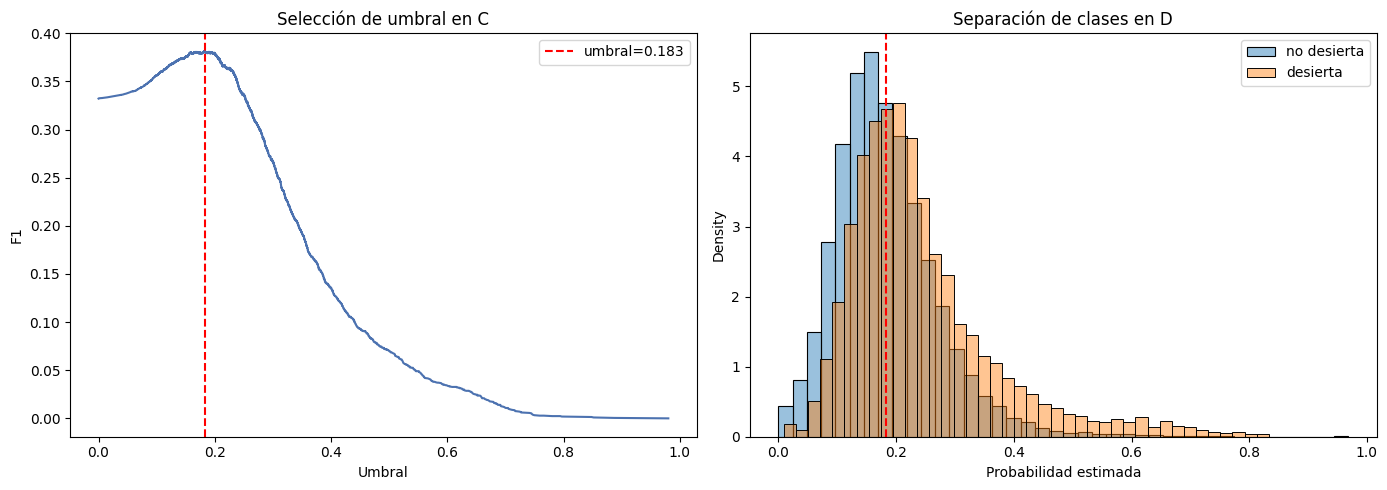

In [42]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(curva_umbral["threshold"], curva_umbral["f1"])
ax[0].axvline(mejor_threshold, color="red", linestyle="--", label=f"umbral={mejor_threshold:.3f}")
ax[0].set(xlabel="Umbral", ylabel="F1", title="Selección de umbral en C")
ax[0].legend()
for clase, color, etiqueta in ((0, "tab:blue", "no desierta"), (1, "tab:orange", "desierta")):
    sns.histplot(
        proba_test_temporal[y_test_temporal == clase], bins=40, stat="density",
        color=color, alpha=0.45, label=etiqueta, ax=ax[1]
    )
ax[1].axvline(mejor_threshold, color="red", linestyle="--")
ax[1].set(xlabel="Probabilidad estimada", title="Separación de clases en D")
ax[1].legend()
plt.tight_layout()

# Resultados y discusión

La tabla de B compara las tres regresiones con parámetros iniciales comunes y permite medir el aporte de texto y conteos. Comparar sus versiones optimizadas por separado ya no aísla exclusivamente ese aporte. C sirve para seleccionar el umbral; solo D estima el desempeño posterior de la configuración cerrada. No se reporta F1 de entrenamiento como generalización.

Las matrices distinguen falsas alertas y licitaciones desiertas no detectadas. Un organismo podría usar el puntaje para priorizar revisión de bases, pero F1 no representa costos operacionales: faltan costos cuantificados y una evaluación de disponibilidad real de etiquetas. Brier en D describe la calidad de las probabilidades; no se usa para recalibrar.

Los diagnósticos siguientes comparan nulos, monedas, modalidades, categorías, regiones, plazos y longitudes entre A–E. E solo interviene en este diagnóstico sin etiquetas. No se modifica el modelo a partir de estos resultados.

In [43]:
resumen_predicciones = pd.DataFrame([
    {"particion": "B (selección, umbral 0.5)", "n": len(val_hparam), **mejor_resultado_hparam},
    {"particion": "C (selección de umbral)", "n": len(val_umbral), **metricas_umbral},
    {"particion": "D (evaluación final)", "n": len(test_temporal), **metricas_test_temporal}
]).drop(columns=["modelo", "params"])
display(resumen_predicciones)

test_features = construir_features(test_df, referencia=datos)
datos_por_bloque = {**bloques, "E": test_df}
features_por_bloque = {
    "A": X_train_modelos, "B": X_val_hparam, "C": X_val_umbral,
    "D": X_test_temporal, "E": test_features
}
print("Porcentaje de nulos por columna de origen")
display(pd.DataFrame({nombre: df[COLUMNAS_ORIGEN].isna().mean() * 100 for nombre, df in datos_por_bloque.items()}))
print("Medianas de plazos y longitudes")
columnas_estabilidad = ["pub_dias_postulacion", "pub_dias_consultas", "titulo_largo", "descripcion_larga"]
display(pd.DataFrame({nombre: X[columnas_estabilidad].median() for nombre, X in features_por_bloque.items()}))
print("Proporciones de categorías, modalidades, regiones y monedas")
display(pd.concat({
    col: pd.DataFrame({nombre: X[col].value_counts(normalize=True) for nombre, X in features_por_bloque.items()})
    for col in ["pub_moneda", "pub_modalidad", "region", "categoria_principal"]
}, names=["variable", "valor"]).fillna(0))
print("Montos por moneda: no se mezclan unidades")
display(pd.concat({
    nombre: df.groupby("pub_moneda", dropna=False)["pub_monto_estimado"].agg(["count", "median"])
    for nombre, df in datos_por_bloque.items()
}, names=["bloque", "moneda"]))

,particion,n,threshold,f1,precision,recall,ap,roc_auc,brier,tasa_observada,tasa_predicha,matriz_confusion
0,"B (selección, umbral 0.5)",25762,0.500000,0.077713,0.683871,0.041197,0.337993,0.654777,0.150651,0.199752,0.012033,"[[20518, 98], [4934, 212]]"
1,C (selección de umbral),21308,0.182694,0.381445,0.272709,0.634393,0.331766,0.654811,0.150695,0.199221,0.463441,"[[9881, 7182], [1552, 2693]]"
2,D (evaluación final),14579,0.182694,0.379190,0.268794,0.643463,0.344784,0.647093,0.151927,0.202003,0.483572,"[[6479, 5155], [1050, 1895]]"


Porcentaje de nulos por columna de origen


,A,B,C,D,E
pub_fecha,0.000000,0.000000,0.000000,0.000000,0.000000
pub_titulo,0.000000,0.000000,0.042238,0.000000,0.000000
pub_descripcion,0.000000,0.000000,0.042238,0.000000,0.000000
pub_monto_estimado,45.050823,41.813524,41.439835,46.031964,53.135737
pub_moneda,45.067324,41.848459,41.491459,46.038823,53.154061
pub_metodo,0.014301,0.065989,0.075089,0.150902,0.435201
pub_modalidad,0.000000,0.000000,0.000000,0.000000,0.000000
pub_n_items,0.000000,0.000000,0.000000,0.000000,0.000000
pub_cantidad_total,0.000000,0.000000,0.000000,0.000000,0.000000
pub_n_categorias,0.000000,0.000000,0.000000,0.000000,0.000000


Medianas de plazos y longitudes


,A,B,C,D,E
pub_dias_postulacion,9.914,9.965,9.155,9.89,10.257
pub_dias_consultas,3.000,3.000,3.000,3.00,4.000
titulo_largo,48.000,49.000,49.000,49.00,48.000
descripcion_larga,157.000,160.000,159.000,162.00,181.000


Proporciones de categorías, modalidades, regiones y monedas


A  \
variable            valor                                                          
pub_moneda          CLF                                                 0.004224   
                    CLP                                                 0.541945   
                    EUR                                                 0.000011   
                    USD                                                 0.003146   
                    desconocido                                         0.450673   
...                                                                          ...   
categoria_principal Servicios medioambientales                          0.002574   
                    Servicios profesionales, administrativos y cons...  0.088852   
                    Tecnologías de la información, telecomunicacion...  0.048535   
                    Vehículos y equipamiento en general                 0.029130   
                    desconocido                                         0.000209   

                                                                               B  \
variable            valor                                                          
pub_moneda          CLF                                                 0.003610   
                    CLP                                                 0.574412   
                    EUR                                                 0.000000   
                    USD                                                 0.003494   
                    desconocido                                         0.418485   
...                                                                          ...   
categoria_principal Servicios medioambientales                          0.002290   
                    Servicios profesionales, administrativos y cons...  0.112763   
                    Tecnologías de la información, telecomunicacion...  0.052170   
                    Vehículos y equipamiento en general                 0.025037   
                    desconocido                                         0.000078   

                                                                               C  \
variable            valor                                                          
pub_moneda          CLF                                                 0.003895   
                    CLP                                                 0.576966   
                    EUR                                                 0.000047   
                    USD                                                 0.004177   
                    desconocido                                         0.414915   
...                                                                          ...   
categoria_principal Servicios medioambientales                          0.001079   
                    Servicios profesionales, administrativos y cons...  0.099493   
                    Tecnologías de la información, telecomunicacion...  0.058898   
                    Vehículos y equipamiento en general                 0.022714   
                    desconocido                                         0.000141   

                                                                               D  \
variable            valor                                                          
pub_moneda          CLF                                                 0.004321   
                    CLP                                                 0.532204   
                    EUR                                                 0.000000   
                    USD                                                 0.003087   
                    desconocido                                         0.460388   
...                                                                          ...   
categoria_principal Servicios medioambientales                          0.001166   
                    Servicios profesionales,

Montos por moneda: no se mezclan unidades


count        median
bloque moneda                     
A      CLF       384  1.952750e+03
       CLP     49265  6.518000e+06
       EUR         1  2.500000e+07
       USD       286  3.345418e+04
       NaN        15  5.000000e+02
B      CLF        93  2.100000e+03
       CLP     14798  6.500000e+06
       USD        90  3.157700e+04
       NaN         9  3.500000e+03
C      CLF        83  2.614000e+03
       CLP     12294  6.500000e+06
       EUR         1  3.600000e+03
       USD        89  2.320000e+04
       NaN        11  3.500000e+03
D      CLF        63  2.170000e+03
       CLP      7759  8.000000e+06
       USD        45  5.200000e+04
       NaN         1  9.900000e+01
E      CLF       130  2.014060e+03
       CLP     10041  2.427600e+07
       USD        55  5.000000e+04
       NaN         4  5.475000e+03

## Entrenamiento final y submission

Se reentrena con todo 2024 y se conserva el umbral elegido en C. Los conteos de 2025 usan solo publicaciones de 2024. Antes de escribir el CSV se verifican dimensiones, etiquetas binarias, orden de IDs e independencia de los valores de ejemplo de la plantilla.

In [44]:
X_2024 = construir_features(datos)
y_2024 = datos[TARGET].astype(int)
assert mejor_threshold == decisiones_cerradas["umbral"]
for clave, valor in decisiones_cerradas["parametros"].items():
    assert mejor_modelo_config.get_params()[clave] == valor
modelo_final = ajustar_pipeline(clone(mejor_modelo_config), X_2024, y_2024, "ABCD")
proba_test = modelo_final.predict_proba(test_features)[:, 1]
pred_test = (proba_test >= mejor_threshold).astype(int)

def crear_submission(predicciones, plantilla):
    assert plantilla["id"].equals(test_df["id"])
    resultado = pd.DataFrame({"id": test_df["id"], TARGET: predicciones})
    assert list(resultado.columns) == ["id", TARGET]
    assert len(resultado) == 21829 and resultado["id"].is_unique
    assert resultado["id"].equals(test_df["id"])
    assert resultado[TARGET].notna().all() and resultado[TARGET].isin([0, 1]).all()
    return resultado

submission = crear_submission(pred_test, sample_submission_df)
plantilla_alterada = sample_submission_df.assign(y_desierta=1 - pred_test)
pd.testing.assert_frame_equal(submission, crear_submission(pred_test, plantilla_alterada))
auditoria_ajustes = pd.DataFrame(registro_ajustes)
assert (auditoria_ajustes["hasta"] < auditoria_ajustes["limite"]).all()
# Todas las verificaciones críticas preceden a la escritura del archivo.
submission.to_csv("submission_pregunta2.csv", index=False)
display(auditoria_ajustes.groupby("etapa", sort=False).agg(
    ajustes=("n", "size"), registros=("n", "first"), desde=("desde", "min"), hasta=("hasta", "max")
))
display(pd.Series({
    "proporcion_predicha_2025": pred_test.mean(),
    "probabilidad_media_2025": proba_test.mean(),
    "probabilidad_p10": np.quantile(proba_test, 0.1),
    "probabilidad_mediana": np.median(proba_test),
    "probabilidad_p90": np.quantile(proba_test, 0.9)
}))

,ajustes,registros,desde,hasta
etapa,,,,
A,43,90904,2024-01-04 17:06:15+00:00,2024-07-31 23:27:03+00:00
AB,1,116666,2024-01-04 17:06:15+00:00,2024-09-30 23:25:01+00:00
ABC,1,137974,2024-01-04 17:06:15+00:00,2024-11-14 22:17:01+00:00
ABCD,1,152553,2024-01-04 17:06:15+00:00,2024-12-31 22:29:20+00:00


proporcion_predicha_2025    0.539283
probabilidad_media_2025     0.207979
probabilidad_p10            0.096426
probabilidad_mediana        0.191991
probabilidad_p90            0.333425
dtype: float64

In [45]:
submission.head()

,id,y_desierta
0,47254358932,0
1,295671198916,0
2,214756376398,0
3,404842360472,1
4,899379189128,1


Tras una ejecución completa sin errores, `submission_pregunta2.csv` contendrá las columnas `id` y `y_desierta` en el orden de test. La proporción predicha de desiertas depende del umbral F1 y no demuestra por sí sola descalibración. E no tiene etiquetas conocidas.

La disponibilidad inicial de las variables se sustenta en la pauta adjunta; falta una auditoría del proceso de extracción. Tampoco se conocen fechas de disponibilidad de desenlaces. Por ello se excluye el historial supervisado y se mantiene la limitación retrospectiva del protocolo.

D ya tenía resultados visibles antes de esta revisión. Se conservaron las grillas y los cortes; cualquier ajuste posterior motivado por esos resultados impediría tratar D como una evaluación final independiente. Esta revisión no aporta métricas nuevas: deben regenerarse desde un kernel limpio.